# 00 · Data contract and order reconstruction

**Question:** can we trust the file, and what exactly is an "order"?

Everything later (pairing tests, models, the engine, the money estimate) is built on one-row-per-order
tables. This notebook checks the raw file before anything is built on it.

**What we find**
- The arithmetic reconciles exactly: 0 revenue and 0 gross-profit mismatches across 51,177 lines.
- Every Transaction ID belongs to exactly one branch, timestamp, customer and order type, so it is a clean order key.
- Merging different Transaction IDs that share a branch and an exact second (an idea we tested) is not justified:
  30 such collisions exist, close to the ~21 that random arrivals would produce by chance.
- **72% of orders contain only one side of the pair:** 40.9% are drink-only and 30.9% are food-only.
- In mixed orders the first line is a drink exactly half the time, yet what gets added depends on the first line more
  strongly than on the second (notebook 02). The first line behaves like the anchor item, so we treat it as "the
  first item rung at the till". This is an **assumption**: the export does not label ring order.

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from storiespair import data, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

## 1. Load and audit

In [2]:
lines = data.load_lines()
audit = data.audit(lines)
audit

,check,value,rule
0,Rows (product lines),51177,info
1,Orders (Transaction IDs),33887,info
2,Date range,2026-01-01 to 2026-06-30,info
3,Days covered,181,info
4,Line revenue formula mismatches (> $0.02),0,pass if 0
5,Line gross-profit formula mismatches (> $0.02),0,pass if 0
6,Orders spanning >1 branch / time / customer / ...,0,pass if 0
7,Repeated product lines inside one order,132,flag
8,Revenue on repeated lines (USD),741.43,flag
9,Max distinct prices per product x branch,1,info


**Repeated lines.** 132 lines (0.26%) are exact copies of another line in the same order. They could be a double
scan or two identical items rung separately; the file cannot tell us which. They are kept, and the cell below shows
that removing them does not move the order mix.

In [3]:
dup_key = ["transaction_id", "product", "quantity", "unit_price", "discount_rate"]
lines_nodup = lines.drop_duplicates(dup_key)
mix_with = data.build_orders(lines).composition.value_counts(normalize=True)
mix_without = data.build_orders(lines_nodup.assign(line_pos=lines_nodup.groupby("transaction_id").cumcount())).composition.value_counts(normalize=True)
pd.DataFrame({"with repeated lines": mix_with, "without": mix_without}).round(4)

,with repeated lines,without
composition,,
drink only,0.4092,0.4092
food only,0.3086,0.3086
drink + food,0.2822,0.2822


## 2. What is an order?

Candidate definitions:
1. **Transaction ID** (the POS receipt).
2. **Branch + exact second**: merge receipts rung at the same moment (e.g. a group paying separately).
3. **Customer visit**: the same loyalty ID at the same branch on the same day.

If (2) or (3) were common, pairs could be hiding across receipts.

In [4]:
orders = data.build_orders(lines)
col = data.timestamp_collisions(orders)
cust_days = orders[orders.known_customer].groupby(["customer_id", "branch", "day"]).size()
pd.DataFrame({
    "check": ["Branch + exact second shared by >1 receipt (observed)",
              "Expected by pure chance if orders arrive at random",
              "Same customer, same branch, same day, >1 receipt",
              "...as a share of customer-days"],
    "value": [col["observed_collisions"], col["expected_by_chance"], int((cust_days > 1).sum()),
              f"{(cust_days > 1).mean():.2%}"],
})

,check,value
0,Branch + exact second shared by >1 receipt (ob...,30
1,Expected by pure chance if orders arrive at ra...,21.1
2,"Same customer, same branch, same day, >1 receipt",153
3,...as a share of customer-days,0.72%


**Decision:** keep the Transaction ID as the order. Same-second collisions are at chance level (30 vs ~21 expected,
out of 33,887 orders), and repeat same-day visits by one customer are under 1% of customer-days. Merging would add
noise, not reveal hidden pairs.

## 3. Order composition

In [5]:
mix = orders.composition.value_counts()
summary = pd.DataFrame({"orders": mix, "share": (mix / mix.sum()).round(4)})
summary

,orders,share
composition,,
drink only,13865,0.4092
food only,10459,0.3086
drink + food,9563,0.2822


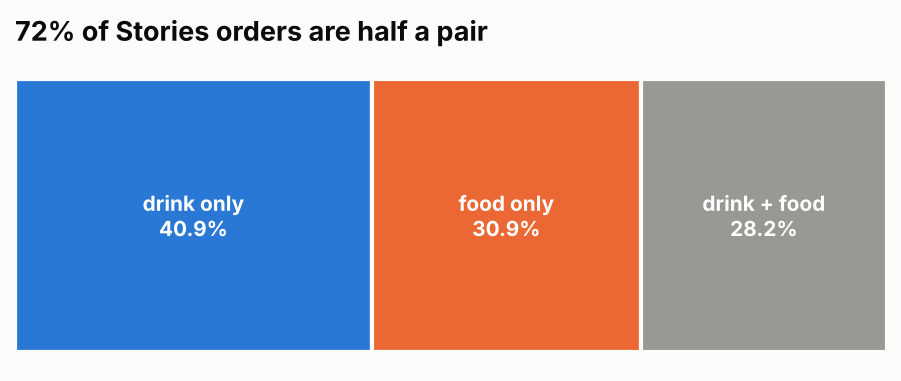

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 2.6))
order = ["drink only", "food only", "drink + food"]
shares = summary.loc[order, "share"].values
colors = [viz.BLUE, viz.ORANGE, viz.GREY]
left = 0
for lab, s_, c in zip(order, shares, colors):
    ax.barh([0], [s_], left=left, color=c, edgecolor=viz.SURFACE, linewidth=2, height=0.55)
    ax.text(left + s_ / 2, 0, f"{lab}\n{s_:.1%}", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += s_
ax.set_xlim(0, 1); ax.set_yticks([]); ax.set_xticks([]); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("72% of Stories orders are half a pair")
viz.savefig(fig, "00_order_mix")
plt.show()

## 4. Line order inside an order

The engine reacts to the **first item rung**. The file does not record ring order, so we check whether the first
line is systematically a drink or a food.

In [7]:
first_is_drink = orders[orders.composition == "drink + food"].first_side.eq("drink").mean()
print(f"Mixed orders whose first line is a drink: {first_is_drink:.1%}")
print("Share of drink lines by position in the order:")
print(lines.groupby("line_pos").side.apply(lambda s: (s == "drink").mean()).round(3).to_string())

Mixed orders whose first line is a drink: 50.0%
Share of drink lines by position in the order:
line_pos
0    0.550
1    0.556
2    0.540


Drink-first and food-first are a coin flip. Line order is still informative: notebook 02 shows the add-on depends
on the first line more strongly than on the second, which is what we would expect if the first line is the anchor
item. We **assume** it is the item rung first. Under this assumption, from the till's point of view:

In [8]:
view = orders.groupby("first_side").agg(orders=("paired", "size"), ends_up_paired=("paired", "mean"))
view.index = ["first item is a drink", "first item is a food"]
view.round(4)

,orders,ends_up_paired
first item is a drink,18644,0.2563
first item is a food,15243,0.3138


Read this as: when a drink is rung first, only about 1 in 4 orders goes on to include food; when a food is rung
first, about 1 in 3 goes on to include a drink. The remaining 69-74% are the audience for a suggestion.

## 5. Save the order table for the next notebooks

In [9]:
os.makedirs("outputs/tables", exist_ok=True)
orders.to_csv("outputs/tables/orders.csv", index=False)
viz.savetable(audit.astype(str), "00_data_audit")
print(f"Saved {len(orders):,} orders.")

Saved 33,887 orders.
